# Angle metadata, inference augmentation and variability

## Findings

**The angle branch's known-angle benefit is small and inconsistent.** With four-flip inference fixed, ensemble OOF log loss changes from **0.22148 to 0.22064**, but the two matched seed effects have opposite signs: **+0.00124 / −0.00278**. Only three of five ensemble folds improve. About **95.0% of the much larger all-row improvement** comes from the 133 missing-angle ships, a cohort absent from the competition test metadata.

**Four-flip inference has more consistent support across seeds.** On the same saved weights, known-angle ensemble loss improves by **0.00229** for the image-only model and **0.00479** for the metadata model. Both individual seeds improve in each architecture, although some held-out folds get worse.

Keep the metadata recipe as a frozen reference and expose `configs/image-only-flips.json` as its simpler, equally budgeted comparison. These results do not establish the angle branch as superior for the known-angle cohort. No default was changed and no new leaderboard submission selected a condition.

## Questions and method

This study tests the optional angle branch and four-flip inference on the same five angle-grouped folds and two training seeds. Both architectures use 30 fixed epochs, the same assignments, optimizer and training augmentation. The final epoch is evaluated without held-out checkpoint selection. All 20 fitted models and all four conditions are retained; the inference ablation reuses their weights.

Known-angle performance is primary because test records have known angles. Angle is an acquisition proxy, and these post-development diagnostics are not an untouched final evaluation. Two training seeds provide descriptive sensitivity, not confidence intervals.

## Data sources

`docs/modeling-study.json` links the source/input/split/producer fingerprints and records each condition. The two producers use the same source revision and fingerprint. Private OOF rows and checkpoints stay outside Git; this notebook renders only aggregate evidence. [Rerun commands and findings](../docs/modeling-study.md).

## Four retained conditions

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = Path.cwd() if Path("docs/modeling-study.json").exists() else Path.cwd().parent
study = json.loads((root / "docs/modeling-study.json").read_text())
assert study["project_id"] == "iceberg"
variants = study["variants"]
order = ["image_only_none", "image_only_flips", "image_and_angle_none", "image_and_angle_flips"]
labels = ["Image only", "Image + flips", "Image + angle", "Image + angle + flips"]
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
rows = ["| Condition | Known-angle OOF loss (1,471 rows) | All-row OOF loss (1,604 rows) | Missing-angle loss (133 ships) |", "|---|---:|---:|---:|"]
for key, label in zip(order, labels, strict=True):
    value = variants[key]
    rows.append(f"| {label} | {value['strata']['known_angle']['log_loss']:.5f} | {value['pooled_oof']['log_loss']:.5f} | {value['strata']['missing_angle']['log_loss']:.5f} |")
display(Markdown("\n".join(rows)))

| Condition | Known-angle OOF loss (1,471 rows) | All-row OOF loss (1,604 rows) | Missing-angle loss (133 ships) |
|---|---:|---:|---:|
| Image only | 0.22377 | 0.22287 | 0.21298 |
| Image + flips | 0.22148 | 0.22030 | 0.20716 |
| Image + angle | 0.22544 | 0.20934 | 0.03124 |
| Image + angle + flips | 0.22064 | 0.20479 | 0.02946 |

### Component effects alongside training-seed variation

Diamonds show the paired-seed OOF ensemble; circles show individual training-seed OOF results on the same folds. Lower loss is better. Two seeds provide descriptive sensitivity, not a confidence interval or a guarantee of future stability.

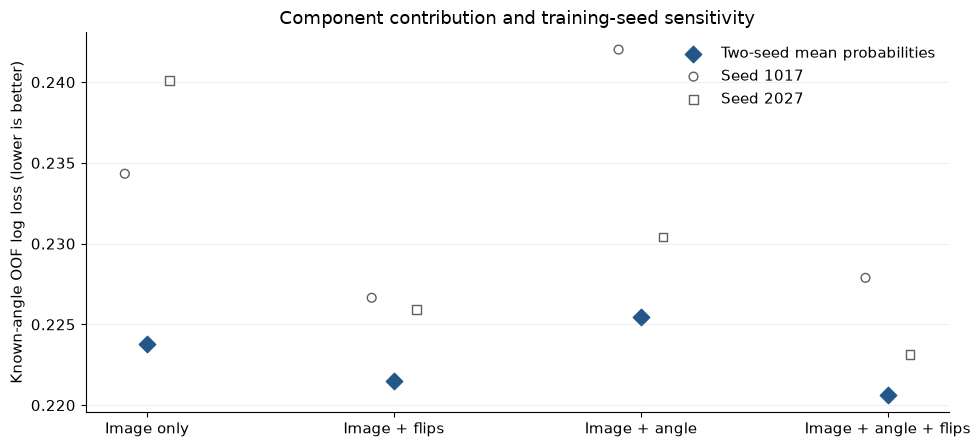

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for index, key in enumerate(order):
    value = variants[key]
    ax.scatter(index, value["strata"]["known_angle"]["log_loss"], marker="D", s=70, color="#235789", label="Two-seed mean probabilities" if index == 0 else None)
    for offset, marker, seed in zip([-0.09, 0.09], ["o", "s"], value["seed_results"], strict=True):
        ax.scatter(index + offset, seed["strata"]["known_angle"]["log_loss"], marker=marker, s=40, facecolors="none", edgecolors="#5b6068", label=f"Seed {seed['seed']}" if index == 0 else None)
ax.set_xticks(range(len(labels)), labels)
ax.set_ylabel("Known-angle OOF log loss (lower is better)")
ax.set_title("Component contribution and training-seed sensitivity")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## Results

Each delta is **after minus before**. A negative loss delta favors the added component. Read the matched seed effects before summarizing a benefit; an aggregate improvement need not occur for every seed or fold.

In [3]:
rows = ["| Controlled change | Known-angle ensemble delta | Known-angle seed deltas | All-row seed deltas |", "|---|---:|---|---|"]
for comparison in study["paired_comparisons"]:
    effects = ", ".join(f"{item['seed']}: {item['delta']:+.5f}" for item in comparison["per_seed_known_angle_deltas"])
    all_effects = ", ".join(f"{item['seed']}: {item['delta']:+.5f}" for item in comparison["per_seed_all_row_deltas"])
    rows.append(f"| {comparison['hypothesis']} | {comparison['known_angle_log_loss_delta']:+.5f} | {effects} | {all_effects} |")
display(Markdown("\n".join(rows)))

| Controlled change | Known-angle ensemble delta | Known-angle seed deltas | All-row seed deltas |
|---|---:|---|---|
| Add angle branch, four-flip inference fixed | -0.00084 | 1017: +0.00124, 2027: -0.00278 | 1017: -0.01358, 2027: -0.01771 |
| Add four-flip inference, image-only weights fixed | -0.00229 | 1017: -0.00768, 2027: -0.01419 | 1017: -0.00794, 2027: -0.01362 |
| Add four-flip inference, metadata weights fixed | -0.00479 | 1017: -0.01413, 2027: -0.00725 | 1017: -0.01375, 2027: -0.00689 |

### Retain every paired fold effect

Each point compares the same held-out fold before and after adding one component. Open circles and squares show the two individual seed comparisons; diamonds compare their mean probabilities. Negative deltas favor the added component. The three panels share one vertical scale. These points describe sensitivity to the retained folds and seeds; they are not independent replicates or confidence intervals.

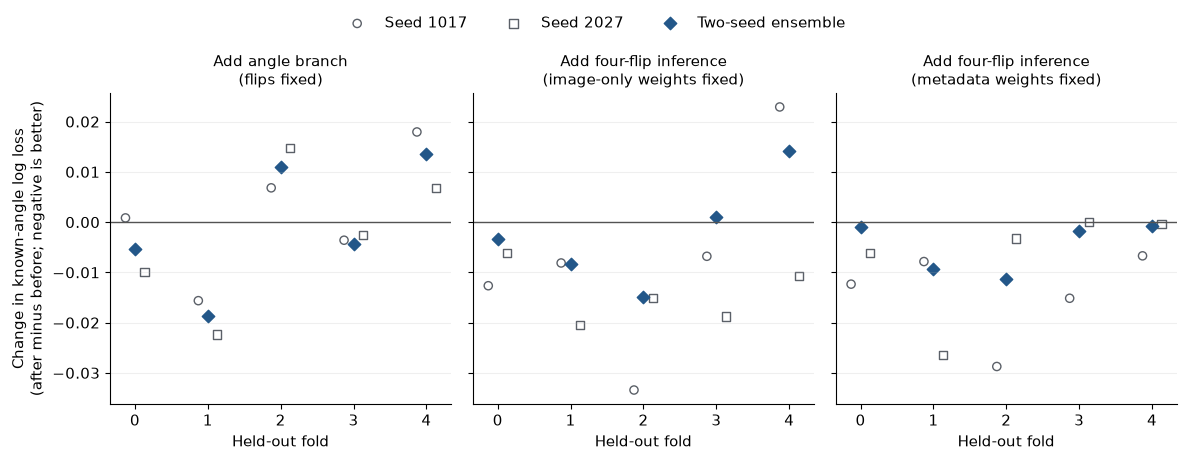

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharey=True)
titles = ["Add angle branch\n(flips fixed)", "Add four-flip inference\n(image-only weights fixed)", "Add four-flip inference\n(metadata weights fixed)"]
for ax, comparison, title in zip(axes, study["paired_comparisons"], titles, strict=True):
    for offset, marker, seed in zip([-0.13, 0.13], ["o", "s"], study["protocol"]["model_seeds"], strict=True):
        points = [item for item in comparison["per_seed_fold_known_angle_deltas"] if item["seed"] == seed]
        ax.scatter([item["fold"] + offset for item in points], [item["delta"] for item in points], marker=marker, s=35, facecolors="none", edgecolors="#5b6068", label=f"Seed {seed}")
    points = comparison["fold_known_angle_deltas"]
    ax.scatter([item["fold"] for item in points], [item["delta"] for item in points], marker="D", s=40, color="#235789", label="Two-seed ensemble")
    ax.axhline(0, color="#535353", linewidth=1)
    ax.set_xticks(range(5))
    ax.set_xlabel("Held-out fold")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Change in known-angle log loss\n(after minus before; negative is better)")
handles, legend_labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

### Calculation checks

The retained verification receipt uses an independent NumPy binary cross-entropy calculation from private OOF files, joined to the raw JSON targets and frozen fold assignments. It checks complete coverage, labels, missingness, all-row and known-angle ensemble scores, individual seeds, and every known-angle seed/fold score. The public notebook uses only aggregates.

In [5]:
verification = study["verification"]["independent_metrics"]
assert verification["status"] == "passed"
assert verification["rows_per_seed"] == 1604
assert verification["known_angle_rows"] == 1471
assert verification["maximum_absolute_error"] < 1e-12
summary = f"**Verified:** {verification['metric_reconciliations']} metric reconciliations; maximum absolute difference {verification['maximum_absolute_error']:.2g}. All four conditions retain all rows and both seeds."
display(Markdown(summary))

**Verified:** 76 metric reconciliations; maximum absolute difference 8.3e-17. All four conditions retain all rows and both seeds.

## Caveats and interpretation

Adding the metadata branch changes parameter count and optimization; it tests the branch as implemented, not the causal value of angle information alone. Matching seed labels does not force identical weight initialization across different architectures. TTA comparisons reuse identical weights. Fold spread and two-seed spread describe different variation sources; split-seed sensitivity is not measured here. Angle is an acquisition proxy rather than a verified scene identifier.

The missing-angle cohort contains only ships and is absent from the test metadata. It can make all-row loss look more favorable without establishing test-cohort improvement. Known-angle validation matches metadata availability, not necessarily the complete test distribution. The two-seed ensemble is evaluated from mean probabilities; its loss is not the arithmetic mean of the two seed losses.

Both fits used four CPU threads, but the earlier metadata CV ran two workers concurrently and image-only CV ran one; elapsed training times are not compared. Deterministic algorithms were not forced. All four conditions are retained; these post-development ablations do not provide untouched-test inference or a new leaderboard result. Operationally, this study depends on immutable inputs, recorded recipes, retained negative results and verifiable delivery: [consumer contract](../docs/consumer-contract.md).